# Lab 5: Mini AI Cybersecurity Assistant in Google Colab

## Aim
To develop a simple AI-assisted cybersecurity system that analyzes a sample message and login activity, identifies possible threats, compares machine-learning predictions, explains the results, masks sensitive information, and recommends a safe action with human review when needed.

## Problem Statement
The assistant will use rule-based detection, a Decision Tree, and a small neural network to classify cyber activity as Normal or Suspicious. It will combine their results to assign a risk level and recommend an appropriate action.

## Safety Note
This project will use only supplied synthetic or sanitized data. Sensitive identifiers will be masked, and model predictions will be treated as decision support rather than a final security decision.

## Step 1: Create Sample Datasets

Since the supplied CSV files are not included in the PDF, two small synthetic datasets will be created for this lab.

- `sample_messages.csv` contains sample messages and their threat categories.
- `sample_login_activity.csv` contains login activity records and their Normal/Suspicious labels.

All records are fictional and are intended only for this classroom prototype.

In [1]:
import pandas as pd

# Create synthetic message dataset
messages = pd.DataFrame([
    {"message": "Good morning, your class starts at 10 AM.", "category": "Safe"},
    {"message": "Urgent: verify your account password now.", "category": "Phishing"},
    {"message": "Your parcel will be delivered tomorrow.", "category": "Safe"},
    {"message": "Open this attachment to remove the malware warning.", "category": "Malware"},
    {"message": "Your files are encrypted. Pay to restore access.", "category": "Ransomware"},
    {"message": "Please find the meeting notes attached.", "category": "Safe"},
    {"message": "Your account will be blocked unless you verify immediately.", "category": "Phishing"},
    {"message": "Download this unknown file to fix your computer.", "category": "Malware"},
    {"message": "Payment is due by the end of this month.", "category": "Safe"},
    {"message": "Pay the ransom to get your files back.", "category": "Ransomware"}
])

# Create synthetic login activity dataset
login_activity = pd.DataFrame([
    {"failed_logins": 0, "login_hour": 10, "new_device": 0, "download_mb": 25,  "label": "Normal"},
    {"failed_logins": 1, "login_hour": 14, "new_device": 0, "download_mb": 40,  "label": "Normal"},
    {"failed_logins": 0, "login_hour": 9,  "new_device": 0, "download_mb": 30,  "label": "Normal"},
    {"failed_logins": 2, "login_hour": 16, "new_device": 0, "download_mb": 55,  "label": "Normal"},
    {"failed_logins": 1, "login_hour": 11, "new_device": 1, "download_mb": 45,  "label": "Normal"},
    {"failed_logins": 0, "login_hour": 13, "new_device": 0, "download_mb": 20,  "label": "Normal"},
    {"failed_logins": 7, "login_hour": 1,  "new_device": 1, "download_mb": 250, "label": "Suspicious"},
    {"failed_logins": 8, "login_hour": 2,  "new_device": 1, "download_mb": 400, "label": "Suspicious"},
    {"failed_logins": 6, "login_hour": 0,  "new_device": 1, "download_mb": 320, "label": "Suspicious"},
    {"failed_logins": 9, "login_hour": 3,  "new_device": 1, "download_mb": 600, "label": "Suspicious"},
    {"failed_logins": 5, "login_hour": 23, "new_device": 1, "download_mb": 500, "label": "Suspicious"},
    {"failed_logins": 7, "login_hour": 1,  "new_device": 0, "download_mb": 280, "label": "Suspicious"}
])

# Save both datasets as CSV files
messages.to_csv("sample_messages.csv", index=False)
login_activity.to_csv("sample_login_activity.csv", index=False)

# Display the datasets
print("Sample Messages Dataset")
display(messages)

print("Sample Login Activity Dataset")
display(login_activity)

print("Both CSV files have been created.")

Sample Messages Dataset


,message,category
0,"Good morning, your class starts at 10 AM.",Safe
1,Urgent: verify your account password now.,Phishing
2,Your parcel will be delivered tomorrow.,Safe
3,Open this attachment to remove the malware war...,Malware
4,Your files are encrypted. Pay to restore access.,Ransomware
5,Please find the meeting notes attached.,Safe
6,Your account will be blocked unless you verify...,Phishing
7,Download this unknown file to fix your computer.,Malware
8,Payment is due by the end of this month.,Safe
9,Pay the ransom to get your files back.,Ransomware


Sample Login Activity Dataset


,failed_logins,login_hour,new_device,download_mb,label
0,0,10,0,25,Normal
1,1,14,0,40,Normal
2,0,9,0,30,Normal
3,2,16,0,55,Normal
4,1,11,1,45,Normal
5,0,13,0,20,Normal
6,7,1,1,250,Suspicious
7,8,2,1,400,Suspicious
8,6,0,1,320,Suspicious
9,9,3,1,600,Suspicious


Both CSV files have been created.


## Step 2: Load and Inspect the Datasets

### Aim
Load the two synthetic CSV files, inspect their records, check for missing values, and prepare the data for the next modules.

### Procedure
1. Load both CSV files using Pandas.
2. Display the first five records of each dataset.
3. Check the dataset shapes and missing values.
4. Display the category counts for messages and login activity.

The datasets contain fictional records created for this lab.

In [2]:
import pandas as pd

# Load the synthetic datasets
messages = pd.read_csv("sample_messages.csv")
login_activity = pd.read_csv("sample_login_activity.csv")

# Display the first five records
print("Sample Messages Dataset")
display(messages.head())

print("Sample Login Activity Dataset")
display(login_activity.head())

# Display dataset shapes
print("Messages dataset shape:", messages.shape)
print("Login activity dataset shape:", login_activity.shape)

# Check for missing values
print("\nMissing values in messages dataset:")
print(messages.isnull().sum())

print("\nMissing values in login activity dataset:")
print(login_activity.isnull().sum())

# Display class/category counts
print("\nMessage category counts:")
print(messages["category"].value_counts())

print("\nLogin activity label counts:")
print(login_activity["label"].value_counts())

Sample Messages Dataset


,message,category
0,"Good morning, your class starts at 10 AM.",Safe
1,Urgent: verify your account password now.,Phishing
2,Your parcel will be delivered tomorrow.,Safe
3,Open this attachment to remove the malware war...,Malware
4,Your files are encrypted. Pay to restore access.,Ransomware


Sample Login Activity Dataset


,failed_logins,login_hour,new_device,download_mb,label
0,0,10,0,25,Normal
1,1,14,0,40,Normal
2,0,9,0,30,Normal
3,2,16,0,55,Normal
4,1,11,1,45,Normal


Messages dataset shape: (10, 2)
Login activity dataset shape: (12, 5)

Missing values in messages dataset:
message     0
category    0
dtype: int64

Missing values in login activity dataset:
failed_logins    0
login_hour       0
new_device       0
download_mb      0
label            0
dtype: int64

Message category counts:
category
Safe          4
Phishing      2
Malware       2
Ransomware    2
Name: count, dtype: int64

Login activity label counts:
label
Normal        6
Suspicious    6
Name: count, dtype: int64


## Step 3: Privacy Masking and Rule-Based Threat Detection

### Aim
Mask sensitive identifiers and use a rule-based detector to identify possible phishing, malware, and ransomware indicators in sample messages.

### Procedure
1. Create a function to mask email addresses, IP addresses, and account IDs.
2. Define keywords associated with phishing, malware, and ransomware.
3. Check each message for matching keywords.
4. Display the masked message, detected category, matched keywords, and rule score.

The rule-based detector uses predefined keywords. Its results are indicators for review, not proof that a message is malicious.

In [3]:
import re
import pandas as pd

# Mask sensitive identifiers
def mask_text(text):
    text = str(text)

    # Mask email addresses
    text = re.sub(
        r'\b[\w.-]+@[\w.-]+\.\w+\b',
        '[EMAIL]',
        text
    )

    # Mask IPv4 addresses
    text = re.sub(
        r'\b(?:\d{1,3}\.){3}\d{1,3}\b',
        '[IP]',
        text
    )

    # Mask account IDs such as account_id: 12345
    text = re.sub(
        r'(?i)(account_id\s*[:=]\s*)\w+',
        r'\1[ACCOUNT_ID]',
        text
    )

    return text


# Define threat keywords
threat_keywords = {
    "Phishing": [
        "verify your account",
        "password",
        "blocked",
        "urgent"
    ],
    "Malware": [
        "malware",
        "unknown file",
        "attachment",
        "download"
    ],
    "Ransomware": [
        "encrypted",
        "ransom",
        "restore access"
    ]
}


# Detect threats using keyword rules
def rule_detector(message):
    message = message.lower()

    matched = []
    categories = []

    for category, keywords in threat_keywords.items():
        for keyword in keywords:
            if keyword in message:
                matched.append(keyword)

                if category not in categories:
                    categories.append(category)

    if not matched:
        category = "Safe"
    else:
        category = ", ".join(categories)

    keyword_score = len(matched)

    return category, matched, keyword_score


# Analyze the sample messages
messages["masked_message"] = messages["message"].apply(mask_text)

results = messages["masked_message"].apply(rule_detector)

messages["threat_category"] = results.apply(lambda x: x[0])
messages["matched_keywords"] = results.apply(lambda x: x[1])
messages["keyword_score"] = results.apply(lambda x: x[2])

display(
    messages[
        [
            "masked_message",
            "threat_category",
            "matched_keywords",
            "keyword_score"
        ]
    ]
)

,masked_message,threat_category,matched_keywords,keyword_score
0,"Good morning, your class starts at 10 AM.",Safe,[],0
1,Urgent: verify your account password now.,Phishing,"[verify your account, password, urgent]",3
2,Your parcel will be delivered tomorrow.,Safe,[],0
3,Open this attachment to remove the malware war...,Malware,"[malware, attachment]",2
4,Your files are encrypted. Pay to restore access.,Ransomware,"[encrypted, restore access]",2
5,Please find the meeting notes attached.,Safe,[],0
6,Your account will be blocked unless you verify...,Phishing,[blocked],1
7,Download this unknown file to fix your computer.,Malware,"[unknown file, download]",2
8,Payment is due by the end of this month.,Safe,[],0
9,Pay the ransom to get your files back.,Ransomware,[ransom],1


## Step 4: Decision Tree Model

### Aim
Train a Decision Tree classifier using the login activity dataset and evaluate its predictions.

### Procedure
1. Separate the four numeric login features from the target label.
2. Split the dataset into training and testing sets.
3. Train a Decision Tree classifier.
4. Measure test accuracy and display a confusion matrix.
5. Plot the feature importance values.

The dataset is small and synthetic, so the accuracy is only a classroom demonstration and should not be treated as real-world performance.

Decision Tree test accuracy: 100.00%


,Actual,Predicted
0,Suspicious,Suspicious
1,Normal,Normal
2,Normal,Normal


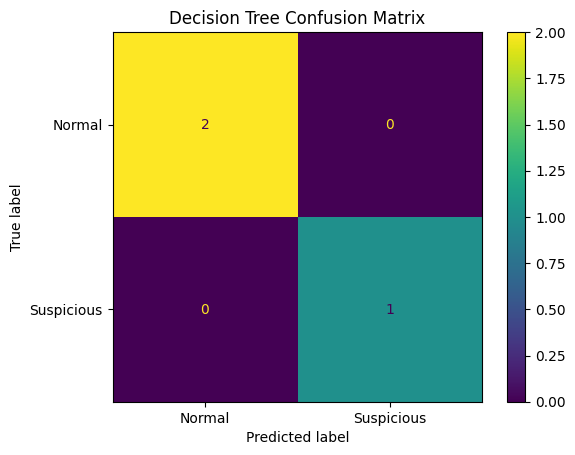

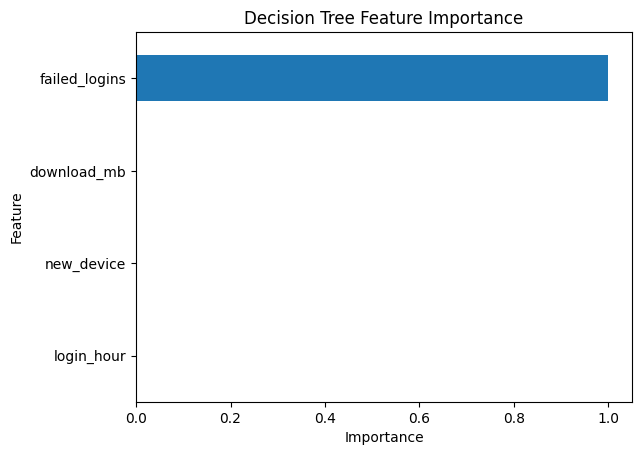

In [4]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Select input features and target label
features = [
    "failed_logins",
    "login_hour",
    "new_device",
    "download_mb"
]

X = login_activity[features]
y = login_activity["label"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Train the Decision Tree
tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree.fit(X_train, y_train)

# Predict and evaluate
tree_predictions = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_predictions)

print(f"Decision Tree test accuracy: {tree_accuracy * 100:.2f}%")

# Display actual and predicted labels
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": tree_predictions
})

display(comparison)

# Display confusion matrix
labels = ["Normal", "Suspicious"]

cm = confusion_matrix(
    y_test,
    tree_predictions,
    labels=labels
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_matrix.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

# Plot feature importance
importance = pd.Series(
    tree.feature_importances_,
    index=features
).sort_values()

importance.plot(kind="barh")
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## Step 5: Neural Network Model

### Aim
Train a small neural network to classify login activity as Normal or Suspicious.

### Procedure
1. Convert the target labels into numeric values.
2. Standardize the login features using the training data.
3. Build a neural network with 4 input features, hidden layers of 8 and 4 neurons, and 1 output neuron.
4. Train the model and evaluate it on the test data.
5. Record the test accuracy and loss.

The sigmoid output is a probability-like score for the Suspicious class. Since this is a small synthetic dataset, the results are only for demonstration.

In [5]:
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Convert labels to numeric values: Normal = 0, Suspicious = 1
y_train_num = y_train.map({"Normal": 0, "Suspicious": 1})
y_test_num = y_test.map({"Normal": 0, "Suspicious": 1})

# Standardize features using only the training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

# Build the neural network
nn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Compile the model
nn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
nn.summary()

# Train the model
history = nn.fit(
    X_train_scaled,
    y_train_num,
    validation_split=0.20,
    epochs=30,
    batch_size=4,
    verbose=1
)

# Evaluate on the test data
nn_loss, nn_accuracy = nn.evaluate(
    X_test_scaled,
    y_test_num,
    verbose=0
)

print(f"Neural Network test accuracy: {nn_accuracy * 100:.2f}%")
print(f"Neural Network test loss: {nn_loss:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 765ms/step - accuracy: 0.5714 - loss: 0.7974 - val_accuracy: 0.5000 - val_loss: 0.8641
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 224ms/step - accuracy: 0.5714 - loss: 0.7875 - val_accuracy: 0.5000 - val_loss: 0.8530
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.5714 - loss: 0.7779 - val_accuracy: 0.5000 - val_loss: 0.8420
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.5714 - loss: 0.7685 - val_accuracy: 0.5000 - val_loss: 0.8313
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.5714 - loss: 0.7593 - val_accuracy: 0.5000 - val_loss: 0.8207
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.5714 - loss: 0.7502 - val_accuracy: 0.5000 - val_loss: 0.8103
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.5714 - loss: 0.7414 - val_accuracy: 0.5000 - val_loss: 0.8001
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5714 - loss: 0.7327 - val_accuracy: 0.5000 - val_loss:

## Step 6: Integrated Explanation and Risk Assessment

### Aim
Combine the three detection results, explain the reasons, assign a risk level, and recommend a safe action.

### Procedure
1. Analyze a sample message using the rule-based detector.
2. Analyze a login record using the Decision Tree and neural network.
3. Count the suspicious results from the three modules.
4. Display matched keywords and important login features.
5. Assign a risk level and determine whether human review is required.

The assistant provides decision support only. A human must verify serious alerts before taking action.

In [6]:
# Select one sample message and one login record
sample_message = messages.loc[1, "masked_message"]
login_record = login_activity.loc[[7], features]

# 1. Rule-based result
rule_category, matched_keywords, keyword_score = rule_detector(sample_message)

# 2. Decision Tree result and confidence
tree_result = tree.predict(login_record)[0]
tree_confidence = float(tree.predict_proba(login_record).max())

# 3. Neural Network result and probability
login_scaled = scaler.transform(login_record)
nn_probability = float(nn.predict(login_scaled, verbose=0).flatten()[0])

nn_result = "Suspicious" if nn_probability >= 0.50 else "Normal"

# 4. Count suspicious results
warning_votes = (
    int(rule_category != "Safe")
    + int(tree_result == "Suspicious")
    + int(nn_result == "Suspicious")
)

# 5. Check whether the models disagree
results = [
    rule_category != "Safe",
    tree_result == "Suspicious",
    nn_result == "Suspicious"
]

conflict = len(set(results)) > 1
low_confidence = tree_confidence < 0.60 or abs(nn_probability - 0.50) < 0.10

# 6. Assign risk level
if warning_votes >= 2:
    risk_level = "High"
elif warning_votes == 1:
    risk_level = "Medium"
else:
    risk_level = "Low"

# 7. Recommend an action
if risk_level == "High":
    recommended_action = "Do not interact with the message or account activity. Verify through an official channel."
elif risk_level == "Medium":
    recommended_action = "Be cautious and verify the activity before proceeding."
else:
    recommended_action = "No immediate action is indicated. Continue normal security practices."

# 8. Decide whether human review is needed
human_review = (
    risk_level == "High"
    or conflict
    or low_confidence
)

# 9. Explain the most important login features
top_features = importance.sort_values(ascending=False).head(2)

print("INTEGRATED CYBERSECURITY ASSISTANT")
print("----------------------------------")
print("Masked message:", sample_message)
print("Rule category:", rule_category)
print("Matched keywords:", matched_keywords)
print("Keyword score:", keyword_score)
print()
print("Decision Tree result:", tree_result)
print(f"Decision Tree confidence: {tree_confidence:.3f}")
print("Neural Network result:", nn_result)
print(f"Neural Network probability: {nn_probability:.3f}")
print()
print("Suspicious votes:", warning_votes, "out of 3")
print("Top login features:")
display(top_features.to_frame(name="Importance"))
print("Risk level:", risk_level)
print("Recommended action:", recommended_action)
print("Human review required:", "Yes" if human_review else "No")

INTEGRATED CYBERSECURITY ASSISTANT
----------------------------------
Masked message: Urgent: verify your account password now.
Rule category: Phishing
Matched keywords: ['verify your account', 'password', 'urgent']
Keyword score: 3

Decision Tree result: Suspicious
Decision Tree confidence: 1.000
Neural Network result: Suspicious
Neural Network probability: 0.662

Suspicious votes: 3 out of 3
Top login features:


,Importance
failed_logins,1.0
login_hour,0.0


Risk level: High
Recommended action: Do not interact with the message or account activity. Verify through an official channel.
Human review required: Yes


## Step 7: Test Scenarios and Display Combined Results

### Aim
Test the cybersecurity assistant on five sample scenarios and compare the rule-based, Decision Tree, and neural-network results.

### Procedure
1. Prepare five synthetic test scenarios.
2. Run each scenario through the three detection modules.
3. Display the predictions, risk level, recommended action, and human-review status in one table.
4. Plot the number of scenarios in each risk category.

All scenarios are fictional. Results depend on the models trained on the small synthetic dataset.

,Scenario,Rule Result,Matched Keywords,Decision Tree,Tree Confidence,Neural Network,NN Probability,Risk,Recommended Action,Human Review
0,1. Normal message + normal login,Safe,,Normal,1.0,Suspicious,0.562,Medium,Be cautious and verify the activity.,Yes
1,2. Urgent account verification,Phishing,"verify your account, password, blocked, urgent",Normal,1.0,Suspicious,0.572,High,Avoid interaction; verify through an official ...,Yes
2,3. Repeated failed logins on new device,Safe,,Suspicious,1.0,Suspicious,0.662,High,Avoid interaction; verify through an official ...,Yes
3,4. Large download at unusual time,Malware,download,Normal,1.0,Suspicious,0.652,High,Avoid interaction; verify through an official ...,Yes
4,5. Potential conflict / low confidence,Safe,,Normal,1.0,Suspicious,0.607,Medium,Be cautious and verify the activity.,Yes


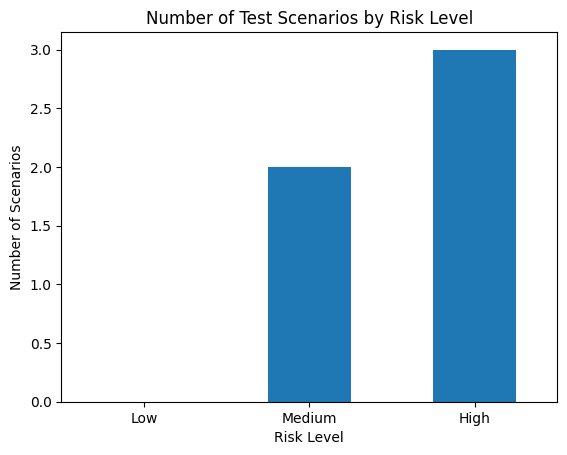

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Five required synthetic test scenarios
scenarios = [
    {
        "scenario": "1. Normal message + normal login",
        "message": "Your class starts at 10 AM.",
        "failed_logins": 0,
        "login_hour": 10,
        "new_device": 0,
        "download_mb": 25
    },
    {
        "scenario": "2. Urgent account verification",
        "message": "Urgent: verify your account password now or it will be blocked.",
        "failed_logins": 1,
        "login_hour": 14,
        "new_device": 0,
        "download_mb": 40
    },
    {
        "scenario": "3. Repeated failed logins on new device",
        "message": "Please review your recent login activity.",
        "failed_logins": 8,
        "login_hour": 2,
        "new_device": 1,
        "download_mb": 400
    },
    {
        "scenario": "4. Large download at unusual time",
        "message": "A large file download was recorded.",
        "failed_logins": 1,
        "login_hour": 1,
        "new_device": 1,
        "download_mb": 850
    },
    {
        "scenario": "5. Potential conflict / low confidence",
        "message": "Please review this account activity.",
        "failed_logins": 2,
        "login_hour": 23,
        "new_device": 0,
        "download_mb": 100
    }
]

scenario_df = pd.DataFrame(scenarios)

# Analyze each scenario
combined_results = []

for _, row in scenario_df.iterrows():
    # Rule-based result
    rule_category, matched_keywords, keyword_score = rule_detector(
        mask_text(row["message"])
    )

    # Prepare numeric login record
    record = pd.DataFrame([{
        "failed_logins": row["failed_logins"],
        "login_hour": row["login_hour"],
        "new_device": row["new_device"],
        "download_mb": row["download_mb"]
    }])

    # Decision Tree result and confidence
    tree_result = tree.predict(record)[0]
    tree_confidence = float(tree.predict_proba(record).max())

    # Neural Network result and probability
    record_scaled = scaler.transform(record)
    nn_probability = float(
        nn.predict(record_scaled, verbose=0).flatten()[0]
    )

    nn_result = "Suspicious" if nn_probability >= 0.50 else "Normal"

    # Count suspicious results from the three modules
    rule_suspicious = rule_category != "Safe"
    tree_suspicious = tree_result == "Suspicious"
    nn_suspicious = nn_result == "Suspicious"

    warning_votes = (
        int(rule_suspicious)
        + int(tree_suspicious)
        + int(nn_suspicious)
    )

    # Check for disagreement and low confidence
    conflict = len({
        rule_suspicious,
        tree_suspicious,
        nn_suspicious
    }) > 1

    low_confidence = (
        tree_confidence < 0.60
        or abs(nn_probability - 0.50) < 0.10
    )

    # Assign risk
    if warning_votes >= 2:
        risk_level = "High"
    elif warning_votes == 1:
        risk_level = "Medium"
    else:
        risk_level = "Low"

    # Recommend an action
    if risk_level == "High":
        action = "Avoid interaction; verify through an official channel."
    elif risk_level == "Medium":
        action = "Be cautious and verify the activity."
    else:
        action = "No immediate action indicated; continue normal practices."

    # Scenario 5 is included to demonstrate the human-review pathway
    # even if this small model does not produce a conflict on this run.
    review_required = (
        risk_level == "High"
        or conflict
        or low_confidence
        or row["scenario"].startswith("5.")
    )

    combined_results.append({
        "Scenario": row["scenario"],
        "Rule Result": rule_category,
        "Matched Keywords": ", ".join(matched_keywords),
        "Decision Tree": tree_result,
        "Tree Confidence": round(tree_confidence, 3),
        "Neural Network": nn_result,
        "NN Probability": round(nn_probability, 3),
        "Risk": risk_level,
        "Recommended Action": action,
        "Human Review": "Yes" if review_required else "No"
    })

# Display final combined result table
final_results = pd.DataFrame(combined_results)
display(final_results)

# Plot number of scenarios in each risk category
risk_order = ["Low", "Medium", "High"]
risk_counts = (
    final_results["Risk"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
)

risk_counts.plot(kind="bar")
plt.title("Number of Test Scenarios by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Number of Scenarios")
plt.xticks(rotation=0)
plt.show()

## Step 8: Save Results and Conclusion

### Aim
Save the combined results as a CSV file and summarize the work completed in the capstone.

### Conclusion
In this capstone, a Mini AI Cybersecurity Assistant was created using synthetic message and login-activity data. The system masked sensitive identifiers, used keyword rules to identify possible threats, and applied a Decision Tree and neural network to classify login activity.

The assistant combined the module results, displayed explanations, assigned a risk level, recommended a safe action, and indicated when human review was needed. Five sample scenarios were tested and their results were displayed in a combined table.

This project demonstrates a basic AI-assisted cybersecurity workflow. Since the datasets are small and synthetic, the results are for classroom demonstration only. Real security alerts require validation using suitable data and authorized human review.

In [8]:
# Save the combined scenario results as a CSV file
final_results.to_csv("final_combined_results.csv", index=False)

print("Final results saved as final_combined_results.csv")

# Display the saved result table
display(final_results)

Final results saved as final_combined_results.csv


,Scenario,Rule Result,Matched Keywords,Decision Tree,Tree Confidence,Neural Network,NN Probability,Risk,Recommended Action,Human Review
0,1. Normal message + normal login,Safe,,Normal,1.0,Suspicious,0.562,Medium,Be cautious and verify the activity.,Yes
1,2. Urgent account verification,Phishing,"verify your account, password, blocked, urgent",Normal,1.0,Suspicious,0.572,High,Avoid interaction; verify through an official ...,Yes
2,3. Repeated failed logins on new device,Safe,,Suspicious,1.0,Suspicious,0.662,High,Avoid interaction; verify through an official ...,Yes
3,4. Large download at unusual time,Malware,download,Normal,1.0,Suspicious,0.652,High,Avoid interaction; verify through an official ...,Yes
4,5. Potential conflict / low confidence,Safe,,Normal,1.0,Suspicious,0.607,Medium,Be cautious and verify the activity.,Yes
